# P3-B: collecting solutions and training an adapter

Could verified ARC solutions supply data for local QLoRA?

These notebooks use **curated aggregate data**, transcribed from the cited reports. They require no model, network, GPU, Docker, or local experiment artifacts. Counts describe the recorded runs through November 5, 2026. Run all cells from a fresh kernel.

A **verified Oracle** is a model-authored program that passes the synthetic-task checks. A **strict new Oracle** also passes the registered provenance and novelty rules. Neither is evidence that the model independently solved a real ARC task.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


## How the experiment worked

Qwen generated candidate programs for ARC Exploration tasks. An independent verifier checked candidates. A separate low-data pilot trained an adapter from one verified 8B solution; the normal gate required five.

## Results

Source: [P3-B local report](../../docs/p3b-local.md).

The data below are aggregate observations, not new model runs.

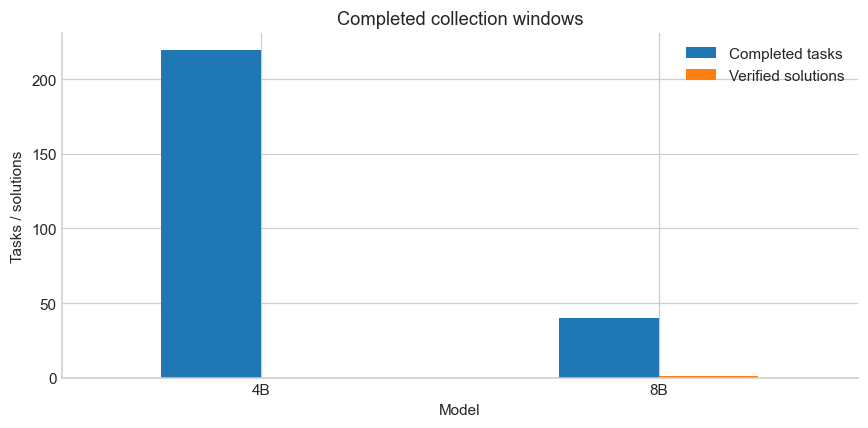

,Model,Completed tasks,Verified solutions
0,4B,220,0
1,8B,40,1


In [2]:
data = pd.DataFrame({'Model': ['4B', '8B'], 'Completed tasks': [220, 40], 'Verified solutions': [0, 1]})
ax = data.set_index('Model')[['Completed tasks', 'Verified solutions']].plot.bar(rot=0, title='Completed collection windows')
ax.set_ylabel('Tasks / solutions')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
data

## What to take away

The bars use different outcomes on the same count scale; one solution came from 40 8B tasks. Synthetic 4B canary training demonstrated the adapter mechanism only. The real one-example 8B adapter trained, but the five-task comparison had four adapter-condition task errors and was rolled back; it did not demonstrate an accuracy gain.